# Task 4: indexes and their effect on runtime

Task 4 asks for three things (brief, section "Task 4: Indices and their Effect on Runtime"):

| # | Requirement | Where |
|---|---|---|
| 1 | Use `EXPLAIN` to see how each query runs, then try to speed queries up with `CREATE INDEX` | Part A (plans), Part B (candidates) |
| 2 | For each index: run the query **5 times** on the **largest database** (all 5 resale files) and compare with the un-indexed runtime on the same database size | Part B (every candidate), Part C (final set) |
| 3 | Bar chart of average runtime **with and without** indexes | Part D |
| 4 | Report: the `CREATE INDEX` statements, the plot, a discussion; supplementary `.sql` file and the raw measurement file | `indexes.sql`, `results/task4_measurements.csv`, `task4_report.md` |

**How this notebook is organised**

- **Part A** shows how each query runs today (`EXPLAIN ANALYZE`) and which tables it scans.
- **Part B** tests 9 candidate indexes **one at a time**: create it, run Q1–Q6 five times each, note whether the planner used it, drop it. This is the evidence for which indexes to keep.
- **Part C** creates the final set from `Task 4/indexes.sql` (the file that is submitted) and measures Q1–Q6 five times without and with it. The results are checked to be identical.
- **Part D** draws the bar chart and prints the tables for the report.
- **Part E** measures what the index costs (size, build time, slower inserts).
- **Part F** shows two things that indexes cannot fix, to back up the discussion.

**Before you run it:** the database must hold **step 5** (987,686 sales; see the README, "Running everything"). Set `DB_NAME` below (or the environment variable `TASK4_DB`). Run all cells top to bottom; nothing else needs editing. The whole notebook takes a few minutes.

## Setup

In [119]:
import hashlib
import json
import os
import platform
import re
import time
from datetime import datetime
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import psycopg

DB_NAME = os.environ.get("TASK4_DB", "hexa_nexus_task4")   # database that holds the housing schema, loaded with STEP 5
RUNS    = 5      # timed runs per query and condition (required by the brief)
WARMUP  = 1      # untimed run before each series, so the first timed run is not slower because of a cold cache
STEP    = 5      # Task 4 is measured on the largest database only

# repository root: the first folder, going upwards, that contains "Task 4"
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "Task 4").is_dir())
QUERY_FILE = ROOT / "Task 3" / "queries.sql"            # the SAME queries as Task 3
INDEX_FILE = ROOT / "Task 4" / "indexes.sql"            # the final CREATE INDEX statements
RESULTS    = ROOT / "Task 4" / "results"
PLANS      = RESULTS / "plans"
PLANS.mkdir(parents=True, exist_ok=True)
MEASUREMENTS = RESULTS / "task4_measurements.csv"       # raw file behind the bar chart: one row per run
SUMMARY      = RESULTS / "task4_summary.csv"            # average per query, with and without index
SCREENING    = RESULTS / "task4_candidate_screening.csv"
SUPPORTING   = RESULTS / "task4_supporting_experiments.csv"
CHART        = RESULTS / "task4_runtime_with_vs_without_index.png"
HEATMAP      = RESULTS / "task4_candidate_screening.png"
ENVIRONMENT  = RESULTS / "task4_environment.json"

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

con = psycopg.connect(dbname=DB_NAME, autocommit=True)
print("connected to", DB_NAME)

connected to hexa_nexus_task4


## Helpers

- `QUERIES` are read from `Task 3/queries.sql`, so Task 3 and Task 4 run exactly the same SQL.
- `run_query` times a query like Task 3 did: wall-clock time from sending the query until all rows have arrived (`time.perf_counter` around `execute` + `fetchall`).
- `measure_block` runs each query `WARMUP` + `RUNS` times and keeps the `RUNS` timed ones. It also stores a fingerprint (MD5) of the result so we can prove an index never changes an answer.
- `plan` returns the `EXPLAIN` text of a query; `uses_index` checks whether a given index appears in it.

In [120]:
QUERIES = dict(re.findall(r"-- @(Q\d)\n(.*?)(?=\n-- @Q\d|\Z)", QUERY_FILE.read_text(), flags=re.S))
print("queries loaded:", list(QUERIES))


def run_query(name, sql=None):
    # Run one query; return (rows, runtime in ms), timed the same way as in Task 3.
    start = time.perf_counter()
    cur = con.execute(sql or QUERIES[name])
    rows = cur.fetchall()
    return rows, (time.perf_counter() - start) * 1000


def fingerprint(rows):
    return hashlib.md5(repr(rows).encode()).hexdigest()[:12]


def measure_block(condition, names=None, runs=RUNS, warmup=WARMUP, sqls=None, **extra):
    # Time each query `runs` times after `warmup` untimed runs. Returns a list of dicts (one per run).
    recs = []
    for name in (names or QUERIES):
        sql = (sqls or {}).get(name)
        for _ in range(warmup):
            run_query(name, sql)
        for run in range(1, runs + 1):
            rows, ms = run_query(name, sql)
            recs.append({"condition": condition, "query": name, "run": run, "runtime_ms": round(ms, 3),
                         "rows_returned": len(rows), "result_md5": fingerprint(rows), **extra})
    return recs


def plan(name, analyze=False, sql=None):
    prefix = "EXPLAIN (ANALYZE, BUFFERS) " if analyze else "EXPLAIN "
    text = (sql or QUERIES[name]).strip().rstrip(";")
    return "\n".join(r[0] for r in con.execute(prefix + text).fetchall())


def uses_index(plan_text, index_names):
    return any(i in plan_text for i in index_names)


def normalise_plan(text):
    # plan structure without the cost estimates, so two plans can be compared for "did the plan change?"
    return re.sub(r"\s*\(cost=[^)]*\)", "", text)


def scan_types(plan_text):
    kinds = ["Index Only Scan", "Index Scan", "Bitmap Index Scan", "Seq Scan"]
    return "; ".join(k for k in kinds if k in plan_text)


def housing_indexes():
    return con.execute('''SELECT tablename, indexname, pg_relation_size(('housing.' || indexname)::regclass) / 1048576.0
                          FROM pg_indexes WHERE schemaname = 'housing' ORDER BY tablename, indexname''').fetchall()


def db_snapshot():
    return con.execute('''
        SELECT (SELECT count(*) FROM housing.resale_transaction),
               (SELECT min(transaction_month) FROM housing.resale_transaction),
               (SELECT max(transaction_month) FROM housing.resale_transaction),
               pg_database_size(current_database()),
               (SELECT sum(pg_total_relation_size(c.oid)) FROM pg_class c JOIN pg_namespace n ON n.oid = c.relnamespace
                WHERE n.nspname = 'housing' AND c.relkind = 'r')''').fetchone()

queries loaded: ['Q1', 'Q2', 'Q3', 'Q4', 'Q5', 'Q6']


## Pre-check: is this the largest database?

Task 4 must be measured on the database with **all** resale files. That is step 5: **987,686** sales from 1990-01 to the latest month. The cell stops if the database is anything else.

In [121]:
transactions, first_month, last_month, db_bytes, housing_bytes = db_snapshot()
print(f"transactions: {transactions:,} ({first_month} to {last_month})")
print(f"database size: {db_bytes / 2**20:.1f} MB | housing tables incl. indexes: {housing_bytes / 2**20:.1f} MB")
assert transactions == 987_686, (
    f"This database has {transactions:,} sales, not 987,686 (step 5). Reload it with the step-5 CSVs: "
    "DROP SCHEMA housing CASCADE; run schema.sql; run load_data.sql with data/processed_steps/step_5/.")

# Make the starting state canonical: no leftover Task 4 indexes, fresh statistics and visibility map.
leftover = [i for _, i, _ in housing_indexes() if i.startswith("idx_")]
for i in leftover:
    con.execute(f"DROP INDEX housing.{i}")
for t in ["town", "hdb_building", "hdb_flat", "resale_transaction", "hawker_centre", "proximity_level", "proximity"]:
    con.execute(f"VACUUM (ANALYZE) housing.{t}")
print("removed leftover idx_* indexes:", leftover or "none")
print("indexes now (only the ones PostgreSQL creates for PRIMARY KEY / UNIQUE / EXCLUDE):")
display(pd.DataFrame(housing_indexes(), columns=["table", "index", "size_mb"]).round(2))

env = {
    "measured_at": datetime.now().isoformat(timespec="seconds"),
    "postgres": con.execute("SHOW server_version").fetchone()[0],
    "os": platform.platform(), "cpu_count": os.cpu_count(),
    **{k: con.execute(f"SHOW {k}").fetchone()[0]
       for k in ["shared_buffers", "work_mem", "max_parallel_workers_per_gather", "jit", "random_page_cost"]},
    "transactions": transactions, "db_size_mb": round(db_bytes / 2**20, 2),
}
ENVIRONMENT.write_text(json.dumps(env, indent=2))
print(json.dumps(env, indent=2))

transactions: 987,686 (1990-01-01 to 2026-09-01)
database size: 130.7 MB | housing tables incl. indexes: 122.6 MB
removed leftover idx_* indexes: ['idx_resale_transaction_month']
indexes now (only the ones PostgreSQL creates for PRIMARY KEY / UNIQUE / EXCLUDE):


,table,index,size_mb
0,hawker_centre,hawker_centre_centre_name_key,0.01562500000000000000
1,hawker_centre,hawker_centre_pkey,0.01562500000000000000
2,hdb_building,building_address_unique,0.52343750000000000000
3,hdb_building,hdb_building_pkey,0.23437500000000000000
4,hdb_flat,flat_profile_unique,7.4140625000000000
5,hdb_flat,hdb_flat_pkey,3.1562500000000000
6,proximity,proximity_pkey,0.67968750000000000000
7,proximity_level,level_no_overlap,0.00781250000000000000
8,proximity_level,proximity_level_label_key,0.01562500000000000000
9,proximity_level,proximity_level_pkey,0.01562500000000000000


{
  "measured_at": "2026-11-01T01:37:07",
  "postgres": "18.4 (Postgres.app)",
  "os": "macOS-27.0.1-arm64-arm-64bit-Mach-O",
  "cpu_count": 10,
  "shared_buffers": "128MB",
  "work_mem": "4MB",
  "max_parallel_workers_per_gather": "2",
  "jit": "on",
  "random_page_cost": "4",
  "transactions": 987686,
  "db_size_mb": 130.71
}


# Part A: how does each query run today?

`EXPLAIN (ANALYZE, BUFFERS)` runs the query and prints the plan PostgreSQL chose, with the real time and rows per step. Two things matter for indexes:

1. **Which tables are read with a `Seq Scan`, and how many of their rows are thrown away** (`Rows Removed by Filter`). A selective filter that discards most rows is the classic case for an index.
2. **How many rows a query needs.** If a query needs most of a table, reading it in order (sequential scan) is cheaper than jumping around through an index, so PostgreSQL will not use one.

The plans are saved to `Task 4/results/plans/` for the report.

In [122]:
for name in QUERIES:
    text = plan(name, analyze=True)
    (PLANS / f"{name.lower()}_without_index.txt").write_text(text)

def show_scans(name):
    # one row per sequential scan: table, rows returned and rows thrown away (totals over all parallel workers)
    lines = (PLANS / f"{name.lower()}_without_index.txt").read_text().splitlines()
    rows = []
    for i, line in enumerate(lines):
        m = re.search(r"(Parallel Seq Scan|Seq Scan) on (\w+)", line)
        a = re.search(r"actual time=[\d.]+\.\.[\d.]+ rows=([\d.]+) loops=(\d+)", line)
        if not (m and a):
            continue
        loops = int(a.group(2))
        filt, removed = "", 0
        for nxt in lines[i + 1:i + 4]:
            if "Filter:" in nxt and "Rows Removed" not in nxt and not filt:
                filt = nxt.split("Filter:", 1)[1].strip()
            if "Rows Removed by Filter:" in nxt:
                removed = int(float(nxt.split(":", 1)[1]))
        out = int(round(float(a.group(1)) * loops))
        rows.append({"query": name, "scan": m.group(1), "table": m.group(2), "rows_kept": out,
                     "rows_thrown_away": removed * loops, "share_kept_pct": round(100 * out / max(out + removed * loops, 1), 1),
                     "filter": filt[:70]})
    return rows

scans = pd.DataFrame([r for n in QUERIES for r in show_scans(n)])
display(scans[scans["table"] == "resale_transaction"].reset_index(drop=True))
print("Execution time of the EXPLAIN ANALYZE runs (includes some overhead):")
for n in QUERIES:
    print(n, re.search(r"Execution Time: ([\d.]+) ms", (PLANS / f"{n.lower()}_without_index.txt").read_text()).group(1), "ms")

,query,scan,table,rows_kept,rows_thrown_away,share_kept_pct,filter
0,Q1,Parallel Seq Scan,resale_transaction,80306,907380,8.1,((transaction_month >= '2022-01-01'::date) AND...
1,Q2,Parallel Seq Scan,resale_transaction,987686,0,100.0,
2,Q3,Seq Scan,resale_transaction,987686,0,100.0,
3,Q4,Parallel Seq Scan,resale_transaction,987686,0,100.0,
4,Q5,Seq Scan,resale_transaction,987686,0,100.0,
5,Q6,Parallel Seq Scan,resale_transaction,80306,907380,8.1,((transaction_month >= '2022-01-01'::date) AND...


Execution time of the EXPLAIN ANALYZE runs (includes some overhead):
Q1 57.092 ms
Q2 458.565 ms
Q3 267.642 ms
Q4 88.332 ms
Q5 264.497 ms
Q6 41.066 ms


**Reading the plans** (the fact table `resale_transaction` is the only large one; the others have 27 to 147,000 rows):

| Query | What it needs from `resale_transaction` | Index can help? |
|---|---|---|
| Q1 | only 2022–2024 (about 8% of the rows) but the plan scans all of them and discards the rest | **yes**: filter on `transaction_month` |
| Q6 | same date filter (2022–2024) | **yes**: same filter |
| Q2 | every row (buckets over all sales) and a sort that spills to disk | no: needs all rows |
| Q3 | every row of 3-room flats, **and** the subquery is evaluated twice (materialised) | unlikely: needs ~31% of rows |
| Q4 | ~94% of the rows (all flats whose building has a hawker centre in range) | no: needs almost all rows |
| Q5 | ~63% of the rows | no: needs most rows |

These are hypotheses. Part B tests all of them, including the ones we expect to fail.

# Part B: test candidate indexes one at a time

Nine candidates, chosen from the plans in Part A and from the schema. The schema already has indexes for every `PRIMARY KEY`, `UNIQUE` and `EXCLUDE` constraint, but PostgreSQL does **not** index foreign-key columns automatically, so those are natural candidates too.

| ID | Index | Reason to try it |
|---|---|---|
| C1 | `resale_transaction (transaction_month)` | date range filter in Q1 and Q6 |
| C2 | `resale_transaction (transaction_month) INCLUDE (flat_id, resale_price)` | same, but covering: could allow an index-only scan |
| C3 | `resale_transaction USING brin (transaction_month)` | same, tiny; works because rows are stored roughly in date order |
| C4 | `resale_transaction (flat_id)` | foreign key, join column of every query |
| C5 | `resale_transaction (flat_id) INCLUDE (transaction_month, resale_price)` | covering version of C4 for Q3–Q5 |
| C6 | `hdb_flat (flat_type)` | equality filter in Q1, Q3, Q6 |
| C7 | `hdb_building (town_id)` | foreign key, joined in every query |
| C8 | `proximity (hawker_id)` | foreign key, joined in Q5 and Q6 (the primary key starts with `building_id`) |
| C9 | `proximity (building_id, distance_m, hawker_id)` | `MIN(distance_m)` per building (Q4, Q5), `DISTINCT ON` (Q6) |

**Protocol for each candidate:** create it, `ANALYZE` the table, record which scans the plan uses and whether the index appears, run Q1–Q6 (1 warm-up + 5 timed runs each), drop it. The un-indexed baseline is measured **before the first and after the last candidate**, which also tells us how much run-to-run drift to expect.

**When is a change "noticeable"?** Two conditions must both hold:

1. **The plan changed.** The `EXPLAIN` plan with the index differs from the plan without it. If the plan is identical, the index is not involved in running the query, so any runtime difference is run-to-run noise by construction.
2. **The runtime moved beyond noise.** The average differs from the pooled baseline by more than **10%** *and* by more than **2 standard deviations** of the baseline runs.

In [123]:
CANDIDATES = [
    ("C1", "idx_resale_transaction_month", "resale_transaction",
     "CREATE INDEX idx_resale_transaction_month ON housing.resale_transaction (transaction_month)"),
    ("C2", "idx_resale_month_covering", "resale_transaction",
     "CREATE INDEX idx_resale_month_covering ON housing.resale_transaction (transaction_month) INCLUDE (flat_id, resale_price)"),
    ("C3", "idx_resale_month_brin", "resale_transaction",
     "CREATE INDEX idx_resale_month_brin ON housing.resale_transaction USING brin (transaction_month)"),
    ("C4", "idx_resale_flat_id", "resale_transaction",
     "CREATE INDEX idx_resale_flat_id ON housing.resale_transaction (flat_id)"),
    ("C5", "idx_resale_flat_covering", "resale_transaction",
     "CREATE INDEX idx_resale_flat_covering ON housing.resale_transaction (flat_id) INCLUDE (transaction_month, resale_price)"),
    ("C6", "idx_flat_type", "hdb_flat",
     "CREATE INDEX idx_flat_type ON housing.hdb_flat (flat_type)"),
    ("C7", "idx_building_town", "hdb_building",
     "CREATE INDEX idx_building_town ON housing.hdb_building (town_id)"),
    ("C8", "idx_proximity_hawker", "proximity",
     "CREATE INDEX idx_proximity_hawker ON housing.proximity (hawker_id)"),
    ("C9", "idx_proximity_building_dist", "proximity",
     "CREATE INDEX idx_proximity_building_dist ON housing.proximity (building_id, distance_m, hawker_id)"),
]
ALL_IDX = [c[1] for c in CANDIDATES]


def drop_all():
    for i in ALL_IDX:
        con.execute(f"DROP INDEX IF EXISTS housing.{i}")


def with_indexes(label, ddls, idx_names, tables):
    # create the given indexes, measure Q1-Q6, drop them again; returns (records, build_ms, size_mb)
    drop_all()
    t0 = time.perf_counter()
    for d in ddls:
        con.execute(d)
    build_ms = (time.perf_counter() - t0) * 1000
    for t in tables:
        con.execute(f"VACUUM (ANALYZE) housing.{t}")
    size_mb = sum(con.execute("SELECT pg_relation_size(%s::regclass)", (f"housing.{i}",)).fetchone()[0] for i in idx_names) / 2**20
    plans = {q: plan(q) for q in QUERIES}
    recs = measure_block(label)
    for r in recs:
        r["index_used"] = uses_index(plans[r["query"]], idx_names)
        r["plan_changed"] = normalise_plan(plans[r["query"]]) != BASE_PLANS[r["query"]]
        r["scans_in_plan"] = scan_types(plans[r["query"]])
    drop_all()
    for t in tables:
        con.execute(f"VACUUM (ANALYZE) housing.{t}")
    return recs, build_ms, size_mb


drop_all()
BASE_PLANS = {q: normalise_plan(plan(q)) for q in QUERIES}      # plan structure of every query without any extra index
screen, meta = [], []
base_start = measure_block("BASELINE_START")
screen += base_start
print("BASELINE_START", pd.DataFrame(base_start).groupby("query")["runtime_ms"].mean().round(0).to_dict())

for cid, idx, table, ddl in CANDIDATES:
    recs, build_ms, size_mb = with_indexes(cid, [ddl], [idx], [table])
    for r in recs:
        r["candidate"] = cid
    screen += recs
    meta.append({"candidate": cid, "index": idx, "table": table, "ddl": ddl, "build_ms": round(build_ms, 1), "size_mb": round(size_mb, 2)})
    print(cid, idx, pd.DataFrame(recs).groupby("query")["runtime_ms"].mean().round(0).to_dict())

base_end = measure_block("BASELINE_END")
screen += base_end
print("BASELINE_END  ", pd.DataFrame(base_end).groupby("query")["runtime_ms"].mean().round(0).to_dict())

screen_df = pd.DataFrame(screen)
screen_df.insert(0, "step", STEP)
screen_df.to_csv(SCREENING, index=False)
meta_df = pd.DataFrame(meta)
print("\nsaved", len(screen_df), "screening measurements to", SCREENING.relative_to(ROOT))

BASELINE_START {'Q1': 26.0, 'Q2': 407.0, 'Q3': 209.0, 'Q4': 74.0, 'Q5': 209.0, 'Q6': 33.0}
C1 idx_resale_transaction_month {'Q1': 15.0, 'Q2': 404.0, 'Q3': 212.0, 'Q4': 74.0, 'Q5': 205.0, 'Q6': 35.0}
C2 idx_resale_month_covering {'Q1': 14.0, 'Q2': 414.0, 'Q3': 213.0, 'Q4': 78.0, 'Q5': 219.0, 'Q6': 35.0}
C3 idx_resale_month_brin {'Q1': 16.0, 'Q2': 408.0, 'Q3': 214.0, 'Q4': 70.0, 'Q5': 214.0, 'Q6': 26.0}
C4 idx_resale_flat_id {'Q1': 21.0, 'Q2': 396.0, 'Q3': 214.0, 'Q4': 73.0, 'Q5': 205.0, 'Q6': 61.0}
C5 idx_resale_flat_covering {'Q1': 21.0, 'Q2': 392.0, 'Q3': 214.0, 'Q4': 71.0, 'Q5': 210.0, 'Q6': 44.0}
C6 idx_flat_type {'Q1': 22.0, 'Q2': 403.0, 'Q3': 213.0, 'Q4': 72.0, 'Q5': 208.0, 'Q6': 32.0}
C7 idx_building_town {'Q1': 21.0, 'Q2': 399.0, 'Q3': 214.0, 'Q4': 74.0, 'Q5': 209.0, 'Q6': 32.0}
C8 idx_proximity_hawker {'Q1': 21.0, 'Q2': 397.0, 'Q3': 216.0, 'Q4': 74.0, 'Q5': 215.0, 'Q6': 31.0}
C9 idx_proximity_building_dist {'Q1': 21.0, 'Q2': 395.0, 'Q3': 214.0, 'Q4': 69.0, 'Q5': 203.0, 'Q6': 30

### Screening result

For every candidate and query: average runtime, the change against the pooled baseline (negative = faster), whether the planner used the index, and whether the change is noticeable under the rule above.

In [124]:
sd = screen_df
base = (sd[sd["condition"].str.startswith("BASELINE")].groupby("query")["runtime_ms"]
          .agg(base_avg="mean", base_std="std").reset_index())
cand = (sd[~sd["condition"].str.startswith("BASELINE")]
          .groupby(["candidate", "query"])
          .agg(avg_ms=("runtime_ms", "mean"), std_ms=("runtime_ms", "std"),
               index_used=("index_used", "max"), plan_changed=("plan_changed", "max"), scans=("scans_in_plan", "first"),
               identical=("result_md5", "nunique")).reset_index().merge(base, on="query"))
cand["change_pct"] = (cand["avg_ms"] - cand["base_avg"]) / cand["base_avg"] * 100
cand["beyond_noise"] = (cand["avg_ms"] - cand["base_avg"]).abs() > np.maximum(0.10 * cand["base_avg"], 2 * cand["base_std"])
cand["noticeable"] = cand["plan_changed"] & cand["beyond_noise"]
cand = cand.merge(meta_df[["candidate", "index", "size_mb", "build_ms"]], on="candidate")

# sanity: no index may change a query result
ref = sd[sd["condition"] == "BASELINE_START"].groupby("query")["result_md5"].first()
bad = sd[~sd["condition"].str.startswith("BASELINE")].merge(ref.rename("ref_md5"), left_on="query", right_index=True)
bad = bad[bad["result_md5"] != bad["ref_md5"]]
print("results identical to the un-indexed ones in every run:", bad.empty)

pivot_change = cand.pivot(index="candidate", columns="query", values="change_pct").round(1)
pivot_note = cand.pivot(index="candidate", columns="query", values="noticeable")
print("\nChange in average runtime vs pooled baseline, %  (negative = faster)")
display(pivot_change)
print("\nNoticeable (plan changed AND runtime beyond noise)?")
display(pivot_note)
print("\nPooled baseline (10 runs per query), ms:")
display(base.round(1))
print("\nIndex size and build time:")
display(meta_df[["candidate", "index", "size_mb", "build_ms"]])
cand.to_csv(RESULTS / "task4_candidate_summary.csv", index=False)

results identical to the un-indexed ones in every run: True

Change in average runtime vs pooled baseline, %  (negative = faster)


query,Q1,Q2,Q3,Q4,Q5,Q6
candidate,,,,,,
C1,-35.8,1.2,0.6,1.0,-5.1,-4.9
C2,-39.3,3.5,1.1,5.8,1.2,-5.7
C3,-31.8,2.2,1.9,-4.3,-1.1,-27.7
C4,-11.2,-1.0,1.9,-0.2,-5.5,66.6
C5,-12.2,-1.9,1.9,-2.8,-2.9,21.0
C6,-8.3,0.9,1.4,-1.4,-3.7,-12.9
C7,-10.7,-0.0,1.7,0.5,-3.2,-12.7
C8,-11.9,-0.6,2.7,0.6,-0.5,-14.2
C9,-11.5,-1.2,1.6,-5.8,-6.1,-19.2



Noticeable (plan changed AND runtime beyond noise)?


query,Q1,Q2,Q3,Q4,Q5,Q6
candidate,,,,,,
C1,True,False,False,False,False,False
C2,True,False,False,False,False,False
C3,True,False,False,False,False,False
C4,False,False,False,False,False,True
C5,False,False,False,False,False,False
C6,False,False,False,False,False,False
C7,False,False,False,False,False,False
C8,False,False,False,False,False,False
C9,False,False,False,False,False,False



Pooled baseline (10 runs per query), ms:


,query,base_avg,base_std
0,Q1,23.7,2.8
1,Q2,399.5,13.3
2,Q3,210.4,2.6
3,Q4,73.3,4.0
4,Q5,216.4,20.7
5,Q6,36.6,6.7



Index size and build time:


,candidate,index,size_mb,build_ms
0,C1,idx_resale_transaction_month,6.73,130.1
1,C2,idx_resale_month_covering,29.73,409.4
2,C3,idx_resale_month_brin,0.02,23.8
3,C4,idx_resale_flat_id,9.72,202.0
4,C5,idx_resale_flat_covering,29.73,495.0
5,C6,idx_flat_type,0.99,29.8
6,C7,idx_building_town,0.09,1.2
7,C8,idx_proximity_hawker,0.23,5.0
8,C9,idx_proximity_building_dist,0.95,3.9


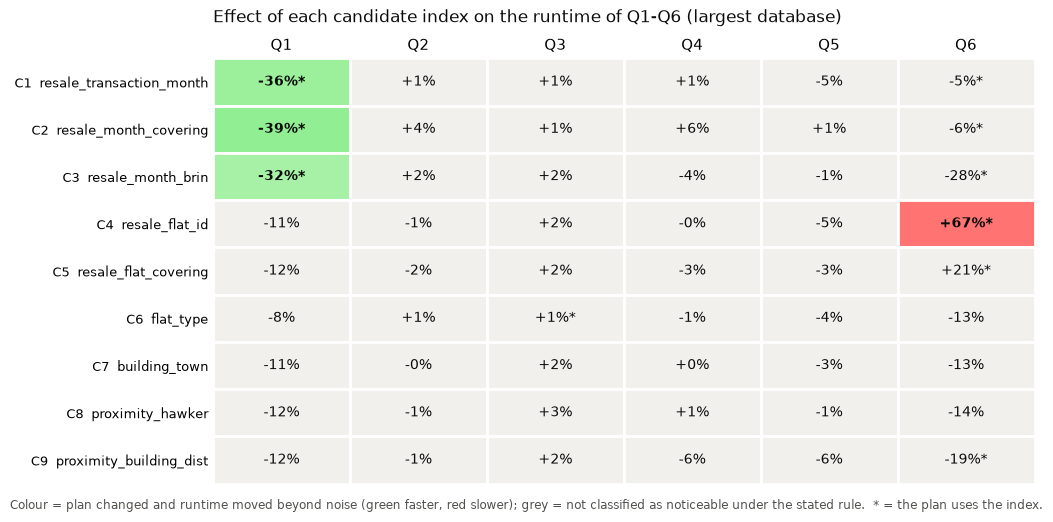

In [125]:
# Heat map for the report: % change per candidate and query, grey = within noise.
queries = sorted(QUERIES)
cands = [c[0] for c in CANDIDATES]
labels = {c[0]: f"{c[0]}  {c[1].replace('idx_', '')}" for c in CANDIDATES}
fig, ax = plt.subplots(figsize=(10.5, 5.2), facecolor="white")
ax.set_xlim(0, len(queries)); ax.set_ylim(len(cands), 0)
for i, c in enumerate(cands):
    for j, q in enumerate(queries):
        row = cand[(cand["candidate"] == c) & (cand["query"] == q)].iloc[0]
        if row["noticeable"]:
            strength = min(abs(row["change_pct"]) / 60, 1)
            color = (1 - 0.65 * strength, 1 - 0.1 * strength, 1 - 0.65 * strength) if row["change_pct"] < 0 else (1, 1 - 0.55 * strength, 1 - 0.55 * strength)
            weight = "bold"
        else:
            color, weight = "#f1f0ec", "normal"
        ax.add_patch(plt.Rectangle((j, i), 1, 1, facecolor=color, edgecolor="white", linewidth=2))
        ax.text(j + 0.5, i + 0.5, f"{row['change_pct']:+.0f}%" + ("*" if row["index_used"] else ""),
                ha="center", va="center", fontsize=10, color="#0b0b0b", fontweight=weight)
ax.set_xticks([j + 0.5 for j in range(len(queries))]); ax.set_xticklabels(queries, fontsize=11)
ax.set_yticks([i + 0.5 for i in range(len(cands))]); ax.set_yticklabels([labels[c] for c in cands], fontsize=9.5)
ax.xaxis.tick_top(); ax.tick_params(length=0)
for s in ax.spines.values():
    s.set_visible(False)
ax.set_title("Effect of each candidate index on the runtime of Q1-Q6 (largest database)", loc="left", fontsize=12, pad=26, color="#0b0b0b")
fig.text(0.01, 0.01, "Colour = plan changed and runtime moved beyond noise (green faster, red slower); grey = not classified as noticeable under the stated rule.  * = the plan uses the index.",
         fontsize=8.5, color="#52514e")
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(HEATMAP, dpi=200)
plt.show()

### Decision

Keep an index only if it makes at least one query **noticeably** faster and does not make another one noticeably slower. Candidates the planner ignores (the plan does not change), or that change nothing beyond noise, are rejected: they would only cost disk space and slow down every `INSERT` (Part E).

**Result.** The plain B-tree on `resale_transaction(transaction_month)` (C1) is submitted. C1, the covering B-tree (C2) and BRIN (C3) all improved Q1 by about 30 to 38%. BRIN also improved Q6 (about -16% to -22% across runs) at 0.02 MB, while the B-tree makes Q6 about 10% slower (+3 ms). The B-tree was chosen for robustness: BRIN only skips table pages when the dates follow the physical row order, which comes from how the data was loaded, whereas a B-tree does not depend on it. The covering B-tree gave only a marginal extra gain on Q1 at four times the size (29.73 MB vs 6.73 MB). The `flat_id` indexes (C4, C5) made Q6 much slower and were rejected. The screening does not show that the B-tree is faster than BRIN.

The next cell tests whether extra indexes **interact** with the chosen one before the final set is fixed.

In [126]:
COMBOS = {
    "C1":                 ["C1"],
    "C1+C6":              ["C1", "C6"],
    "C1+C4":              ["C1", "C4"],
    "C1+all small/FK":    ["C1", "C4", "C6", "C7", "C8", "C9"],
}
by_id = {c[0]: c for c in CANDIDATES}
combo_recs = []
for label, ids in COMBOS.items():
    ddls = [by_id[i][3] for i in ids]
    names = [by_id[i][1] for i in ids]
    tables = sorted({by_id[i][2] for i in ids})
    # drop_all() inside with_indexes removes everything first; recreate all ids of this combination
    recs, build_ms, size_mb = with_indexes(label, ddls, names, tables)
    for r in recs:
        r["combo_size_mb"] = round(size_mb, 2)
    combo_recs += recs
    print(label, pd.DataFrame(recs).groupby("query")["runtime_ms"].mean().round(0).to_dict())

combo = pd.DataFrame(combo_recs)
combo_avg = combo.groupby(["condition", "query"])["runtime_ms"].mean().unstack().round(1)
combo_avg.loc["baseline (pooled)"] = base.set_index("query")["base_avg"].round(1)
display(combo_avg)
combo.assign(step=STEP).to_csv(RESULTS / "task4_combination_tests.csv", index=False)

C1 {'Q1': 17.0, 'Q2': 409.0, 'Q3': 274.0, 'Q4': 74.0, 'Q5': 231.0, 'Q6': 37.0}
C1+C6 {'Q1': 15.0, 'Q2': 416.0, 'Q3': 208.0, 'Q4': 69.0, 'Q5': 207.0, 'Q6': 34.0}
C1+C4 {'Q1': 15.0, 'Q2': 385.0, 'Q3': 211.0, 'Q4': 71.0, 'Q5': 206.0, 'Q6': 35.0}
C1+all small/FK {'Q1': 15.0, 'Q2': 390.0, 'Q3': 208.0, 'Q4': 70.0, 'Q5': 212.0, 'Q6': 32.0}


query,Q1,Q2,Q3,Q4,Q5,Q6
condition,,,,,,
C1,16.7,408.6,274.0,74.4,230.9,36.5
C1+C4,14.5,384.8,211.1,70.6,206.2,34.7
C1+C6,14.8,416.4,207.7,68.7,206.7,34.5
C1+all small/FK,14.7,389.8,208.4,70.2,212.3,32.2
baseline (pooled),23.7,399.5,210.4,73.3,216.4,36.6


# Part C: final measurement, with and without the chosen index

This is the measurement the brief asks for: **5 runs per query on the largest database, without and with the index**. The index is created by executing `Task 4/indexes.sql` itself, so the file we hand in is the file we measured. The plans of the final set are saved next to the plans from Part A.

In [127]:
drop_all()
for t in ["resale_transaction", "hdb_flat", "hdb_building", "proximity", "hawker_centre", "proximity_level", "town"]:
    con.execute(f"VACUUM (ANALYZE) housing.{t}")

transactions, first_month, last_month, db_bytes_without, housing_bytes_without = db_snapshot()
plans_without = {q: plan(q) for q in QUERIES}
without = measure_block("without_index")
print("without index:", pd.DataFrame(without).groupby("query")["runtime_ms"].mean().round(1).to_dict())

con.execute(INDEX_FILE.read_text())                       # <- creates the final index set
final_idx = [i for _, i, _ in housing_indexes() if i.startswith("idx_")]
print("created from indexes.sql:", final_idx)

transactions, first_month, last_month, db_bytes_with, housing_bytes_with = db_snapshot()
plans_with = {q: plan(q) for q in QUERIES}
with_ = measure_block("with_index")
for q in QUERIES:
    (PLANS / f"{q.lower()}_with_index.txt").write_text(plan(q, analyze=True))
print("with index:   ", pd.DataFrame(with_).groupby("query")["runtime_ms"].mean().round(1).to_dict())

meas = pd.DataFrame(without + with_)
meas["index_used"] = meas.apply(lambda r: uses_index(plans_with[r["query"]], final_idx) if r["condition"] == "with_index" else False, axis=1)
meas.insert(0, "step", STEP)
meas.insert(1, "transactions", transactions)
meas.insert(2, "first_month", first_month)
meas.insert(3, "last_month", last_month)
meas.insert(4, "db_size_mb", meas["condition"].map({"without_index": round(db_bytes_without / 2**20, 2), "with_index": round(db_bytes_with / 2**20, 2)}))
meas.insert(5, "housing_size_mb", meas["condition"].map({"without_index": round(housing_bytes_without / 2**20, 2), "with_index": round(housing_bytes_with / 2**20, 2)}))
meas["measured_at"] = datetime.now().isoformat(timespec="seconds")
meas["_order"] = meas["condition"].map({"without_index": 0, "with_index": 1})
meas = meas.sort_values(["query", "_order", "run"]).drop(columns="_order")
meas.to_csv(MEASUREMENTS, index=False)
print(f"\nsaved {len(meas)} measurements ({meas['query'].nunique()} queries x {RUNS} runs x 2 conditions) to {MEASUREMENTS.relative_to(ROOT)}")

same = meas.groupby("query")["result_md5"].nunique().eq(1).all()
print("every query returns exactly the same result with and without the index:", same)
assert same, "an index changed a query result!"

without index: {'Q1': 21.6, 'Q2': 392.2, 'Q3': 212.2, 'Q4': 70.0, 'Q5': 209.5, 'Q6': 32.6}
created from indexes.sql: ['idx_resale_transaction_month']
with index:    {'Q1': 14.9, 'Q2': 386.4, 'Q3': 208.1, 'Q4': 70.3, 'Q5': 205.6, 'Q6': 34.6}

saved 60 measurements (6 queries x 5 runs x 2 conditions) to Task 4/results/task4_measurements.csv
every query returns exactly the same result with and without the index: True


### Summary: average runtime without vs with the index

`Task 3 step 5` is the un-optimised average recorded in Task 3 (`Task 3/results/task3_summary.csv`, step 5). The brief asks to compare against it. If it is far from the `without index` column, this notebook ran on a different machine or setup than Task 3, and the `without index` column of **this** notebook is the fair comparison (same machine, same minute).

In [128]:
agg = (meas.groupby(["query", "condition"])["runtime_ms"].agg(["mean", "std", "min", "max"]).round(2).unstack("condition"))
summary = pd.DataFrame({
    "query": agg.index,
    "avg_without_ms": agg[("mean", "without_index")].values, "std_without_ms": agg[("std", "without_index")].values,
    "avg_with_ms":    agg[("mean", "with_index")].values,    "std_with_ms":    agg[("std", "with_index")].values,
    "min_without_ms": agg[("min", "without_index")].values,  "max_without_ms": agg[("max", "without_index")].values,
    "min_with_ms":    agg[("min", "with_index")].values,     "max_with_ms":    agg[("max", "with_index")].values,
})
summary["change_pct"] = ((summary["avg_with_ms"] - summary["avg_without_ms"]) / summary["avg_without_ms"] * 100).round(1)
summary["speedup_x"] = (summary["avg_without_ms"] / summary["avg_with_ms"]).round(2)
summary["index_used"] = summary["query"].map(lambda q: uses_index(plans_with[q], final_idx))
summary["plan_changed"] = summary["query"].map(lambda q: normalise_plan(plans_without[q]) != normalise_plan(plans_with[q]))
summary["beyond_noise"] = (summary["avg_with_ms"] - summary["avg_without_ms"]).abs() > np.maximum(0.10 * summary["avg_without_ms"], 2 * summary["std_without_ms"])
summary["noticeable"] = summary["plan_changed"] & summary["beyond_noise"]

t3 = pd.read_csv(ROOT / "Task 3" / "results" / "task3_summary.csv")
t3 = t3[t3["step"] == 5].set_index("query")["avg_runtime_ms"]
summary["task3_step5_ms"] = summary["query"].map(t3)
summary["this_vs_task3_x"] = (summary["avg_without_ms"] / summary["task3_step5_ms"]).round(2)
summary.round(2).to_csv(SUMMARY, index=False)
display(summary)
print("\nThis run vs Task 3 for the un-indexed case (1.0 = same machine and setup):", summary["this_vs_task3_x"].tolist())

,query,avg_without_ms,std_without_ms,avg_with_ms,std_with_ms,min_without_ms,max_without_ms,min_with_ms,max_with_ms,change_pct,speedup_x,index_used,plan_changed,beyond_noise,noticeable,task3_step5_ms,this_vs_task3_x
0,Q1,21.56,0.25,14.93,0.32,21.19,21.87,14.55,15.30,-30.8,1.44,True,True,True,True,22.28,0.97
1,Q2,392.17,3.93,386.40,5.59,387.73,397.18,381.05,393.15,-1.5,1.01,False,False,False,False,412.19,0.95
2,Q3,212.18,0.48,208.10,0.89,211.80,213.00,207.10,209.45,-1.9,1.02,False,False,False,False,217.83,0.97
3,Q4,69.97,0.80,70.32,0.49,68.90,70.94,69.75,71.10,0.5,1.00,False,False,False,False,70.58,0.99
4,Q5,209.47,6.36,205.62,2.69,204.58,220.46,202.99,209.28,-1.8,1.02,False,False,False,False,226.61,0.92
5,Q6,32.62,1.64,34.61,0.15,31.02,35.09,34.41,34.76,6.1,0.94,True,True,False,False,33.47,0.97



This run vs Task 3 for the un-indexed case (1.0 = same machine and setup): [0.97, 0.95, 0.97, 0.99, 0.92, 0.97]


# Part D: bar chart, with vs without index

One panel per query (their runtimes differ by a factor of ten, so each has its own y-axis). Bars are the average of 5 runs, dots are the individual runs, and the label above the bar is the average. The text under each title gives the verdict: "plan unchanged" means the index is not part of the query's plan, so the small difference between the bars is run-to-run noise. The dashed line marks the Task 3 step-5 average.

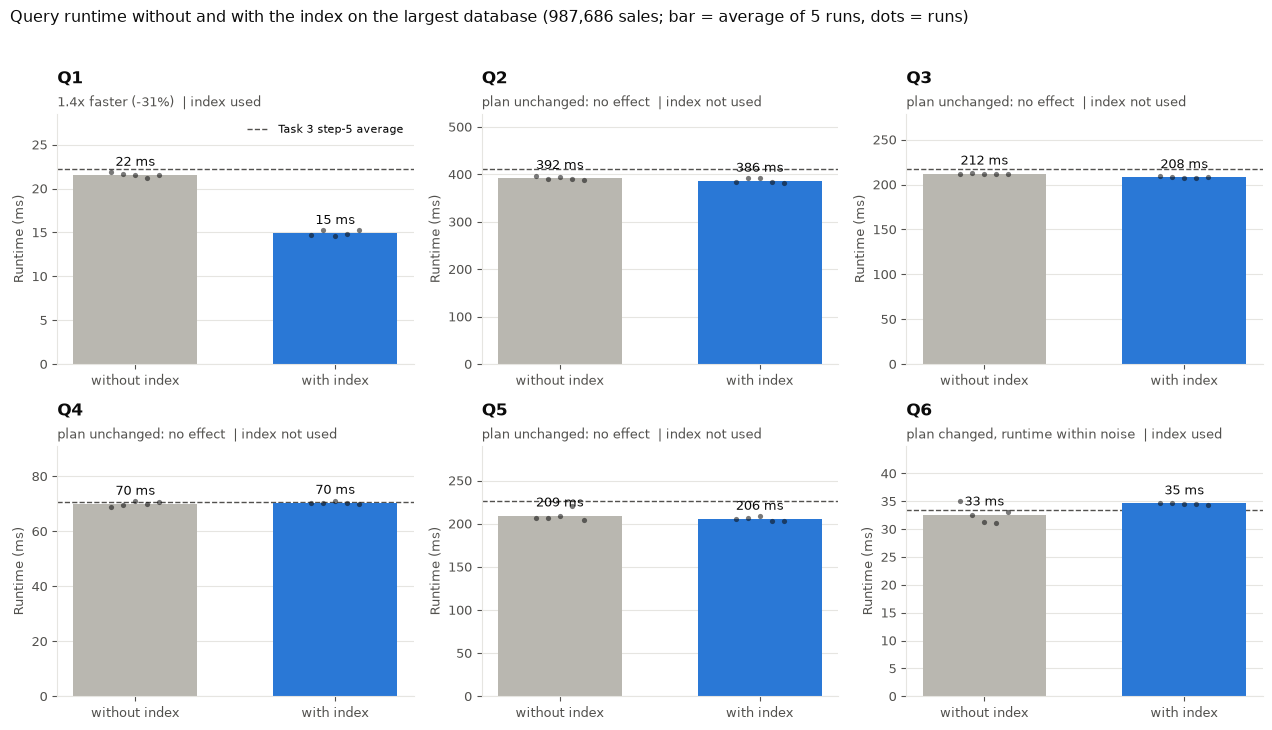

In [129]:
GREY, BLUE, INK, MUTED, GRID = "#b9b7b0", "#2a78d6", "#0b0b0b", "#52514e", "#e6e5e1"
fig, axes = plt.subplots(2, 3, figsize=(13, 7.4), facecolor="white")
for ax, q in zip(axes.flat, sorted(QUERIES)):
    s = summary[summary["query"] == q].iloc[0]
    runs_wo = meas[(meas["query"] == q) & (meas["condition"] == "without_index")]["runtime_ms"]
    runs_w  = meas[(meas["query"] == q) & (meas["condition"] == "with_index")]["runtime_ms"]
    ax.bar([0, 1], [s["avg_without_ms"], s["avg_with_ms"]], color=[GREY, BLUE], width=0.62, zorder=2)
    ax.scatter(np.full(len(runs_wo), 0) + np.linspace(-0.12, 0.12, len(runs_wo)), runs_wo, s=14, color=INK, alpha=0.55, zorder=3, linewidths=0)
    ax.scatter(np.full(len(runs_w), 1) + np.linspace(-0.12, 0.12, len(runs_w)), runs_w, s=14, color=INK, alpha=0.55, zorder=3, linewidths=0)
    if not np.isnan(s["task3_step5_ms"]):
        ax.axhline(s["task3_step5_ms"], color=MUTED, linestyle="--", linewidth=1, zorder=1, label="Task 3 step-5 average")
    top = max(runs_wo.max(), runs_w.max(), s["task3_step5_ms"] if not np.isnan(s["task3_step5_ms"]) else 0)
    ax.set_ylim(0, top * 1.28)
    for x, v in ((0, s["avg_without_ms"]), (1, s["avg_with_ms"])):
        ax.text(x, v + top * 0.03, f"{v:,.0f} ms", ha="center", va="bottom", fontsize=9.5, color=INK, zorder=4)
    if not s["plan_changed"]:
        verdict = "plan unchanged: no effect"
    elif s["noticeable"]:
        verdict = f"{s['speedup_x']:.1f}x faster ({s['change_pct']:+.0f}%)" if s["change_pct"] < 0 else f"{abs(s['change_pct']):.0f}% slower"
    else:
        verdict = "plan changed, runtime within noise"
    ax.set_title(q, loc="left", fontsize=12, fontweight="bold", color=INK, pad=22)
    ax.text(0, 1.03, verdict + ("  | index used" if s["index_used"] else "  | index not used"), transform=ax.transAxes, fontsize=9, color=MUTED)
    ax.set_xticks([0, 1]); ax.set_xticklabels(["without index", "with index"], fontsize=9.5)
    ax.set_ylabel("Runtime (ms)", color=MUTED, fontsize=9)
    ax.grid(axis="y", color=GRID, linewidth=0.8); ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=MUTED, labelsize=9)
axes.flat[0].legend(loc="upper right", fontsize=8, frameon=False)
fig.suptitle("Query runtime without and with the index on the largest database (987,686 sales; bar = average of 5 runs, dots = runs)",
             x=0.01, ha="left", fontsize=11.5, color=INK)
fig.tight_layout(rect=(0, 0, 1, 0.96))
fig.savefig(CHART, dpi=200)
plt.show()

In [130]:
# Paste-ready table for the report
lines = ["| Query | Without index (ms) | With index (ms) | Change | Speed-up | Index used by the plan |", "|---|---|---|---|---|---|"]
for _, s in summary.iterrows():
    change = f"{s['change_pct']:+.0f}%" if s["noticeable"] else ("no effect (plan unchanged)" if not s["plan_changed"] else "within noise")
    speed = f"{s['speedup_x']:.1f}x" if s["noticeable"] else "-"
    lines.append(f"| {s['query']} | {s['avg_without_ms']:,.1f} ± {s['std_without_ms']:,.1f} | {s['avg_with_ms']:,.1f} ± {s['std_with_ms']:,.1f} | {change} | {speed} | {'yes' if s['index_used'] else 'no'} |")
table_md = "\n".join(lines)
print(table_md)
(RESULTS / "task4_results_table.md").write_text(table_md + "\n")

| Query | Without index (ms) | With index (ms) | Change | Speed-up | Index used by the plan |
|---|---|---|---|---|---|
| Q1 | 21.6 ± 0.2 | 14.9 ± 0.3 | -31% | 1.4x | yes |
| Q2 | 392.2 ± 3.9 | 386.4 ± 5.6 | no effect (plan unchanged) | - | no |
| Q3 | 212.2 ± 0.5 | 208.1 ± 0.9 | no effect (plan unchanged) | - | no |
| Q4 | 70.0 ± 0.8 | 70.3 ± 0.5 | no effect (plan unchanged) | - | no |
| Q5 | 209.5 ± 6.4 | 205.6 ± 2.7 | no effect (plan unchanged) | - | no |
| Q6 | 32.6 ± 1.6 | 34.6 ± 0.1 | within noise | - | yes |


521

# Part E: what does the index cost?

An index is not free: it takes disk space, takes time to build, and slows down every `INSERT`/`UPDATE` of the indexed column because PostgreSQL has to maintain it. The next cells measure all three for the final set.

The insert test copies 100,000 existing sales into a scratch table that has the same primary key and the same indexes as the real table at that moment (with and without the new index), and drops it again, so the real tables are never changed. It is repeated 3 times per condition.

In [131]:
def insert_test(reps=3, n=100_000):
    # Insert n existing sales into a scratch copy of the table (same primary key, same indexes as the real
    # table at this moment), so the real table is never touched and gets no dead rows.
    times = []
    for _ in range(reps):
        con.execute("DROP TABLE IF EXISTS housing.t4_scratch")
        con.execute("CREATE TABLE housing.t4_scratch (LIKE housing.resale_transaction INCLUDING ALL)")
        t0 = time.perf_counter()
        con.execute(f'''INSERT INTO housing.t4_scratch
                        SELECT transaction_id, flat_id, transaction_month, resale_price, reported_remaining_lease_months
                        FROM housing.resale_transaction LIMIT {n}''')
        times.append((time.perf_counter() - t0) * 1000)
        con.execute("DROP TABLE housing.t4_scratch")
    return times

# the final index exists at this point (Part C): INCLUDING ALL copies it to the scratch table
ins_with = insert_test()
for i in final_idx:
    con.execute(f"DROP INDEX housing.{i}")
ins_without = insert_test()
t0 = time.perf_counter(); con.execute(INDEX_FILE.read_text()); rebuild_ms = (time.perf_counter() - t0) * 1000

sizes = {i: s for _, i, s in housing_indexes() if i in final_idx}
table_mb = con.execute("SELECT pg_relation_size('housing.resale_transaction') / 1048576.0").fetchone()[0]
cost = pd.DataFrame([{
    "index": i, "size_mb": round(s, 2), "table_heap_mb": round(table_mb, 1), "size_vs_table_pct": round(s / table_mb * 100, 1),
    "build_plus_analyze_ms": round(rebuild_ms, 1),
    "insert_100k_without_ms": round(np.mean(ins_without), 1), "insert_100k_with_ms": round(np.mean(ins_with), 1),
    "insert_slowdown_pct": round((np.mean(ins_with) / np.mean(ins_without) - 1) * 100, 1),
} for i, s in sizes.items()])
display(cost)
print("insert runs without:", [round(x) for x in ins_without], "| with:", [round(x) for x in ins_with])
cost.to_csv(RESULTS / "task4_index_cost.csv", index=False)

,index,size_mb,table_heap_mb,size_vs_table_pct,build_plus_analyze_ms,insert_100k_without_ms,insert_100k_with_ms,insert_slowdown_pct
0,idx_resale_transaction_month,6.73,49.1,13.7,148.4,203.0,288.9,42.4


insert runs without: [206, 227, 176] | with: [300, 283, 283]


# Part F: what indexes cannot fix

Task 3 listed Q2 and Q3 as the first candidates for indexes. Part B shows no index helps them. These two small experiments show **why**, and what would help instead. Neither changes the schema or `queries.sql`; they are evidence for the discussion only.

- **Q2** spills its sort to disk (`Sort Method: external merge  Disk: ...`) because the default `work_mem` is 4 MB. Does raising `work_mem` for the session (to 256 MB) remove the spill, and how much of the runtime is that?
- **Q3** uses its `WITH three_room` subquery twice, so PostgreSQL materialises it (computes it once, stores it, reads it twice). Declaring it `NOT MATERIALIZED` lets the planner fold it into both uses.

In [132]:
sup = []
sup += measure_block("Q2 default work_mem", ["Q2"])

con.execute("SET work_mem = '256MB'")
sup += measure_block("Q2 work_mem=256MB", ["Q2"])
q2_plan_big = plan("Q2", analyze=True)
con.execute("RESET work_mem")

q3_nm = QUERIES["Q3"].replace("three_room AS (", "three_room AS NOT MATERIALIZED (", 1)
assert q3_nm != QUERIES["Q3"]
sup += measure_block("Q3 as written (materialised)", ["Q3"])
sup += measure_block("Q3 NOT MATERIALIZED", ["Q3"], sqls={"Q3": q3_nm})
same_q3 = fingerprint(run_query("Q3")[0]) == fingerprint(run_query("Q3", q3_nm)[0])
print("Q3 result unchanged by NOT MATERIALIZED:", same_q3)
print("Q2 spill with default work_mem :", re.findall(r"Sort Method: external merge\s+Disk: \d+kB", (PLANS / "q2_without_index.txt").read_text())[:1])
print("Q2 spill with work_mem = 256MB :", re.findall(r"Sort Method: external merge\s+Disk: \d+kB", q2_plan_big)[:1] or "none (sorts in memory)")

sup_df = pd.DataFrame(sup)
sup_summary = sup_df.groupby(["query", "condition"], sort=False)["runtime_ms"].agg(avg_ms="mean", std_ms="std").round(1).reset_index()
sup_summary["change_pct_vs_first"] = np.nan
for q, g in sup_summary.groupby("query"):
    first = g.iloc[0]["avg_ms"]
    sup_summary.loc[g.index, "change_pct_vs_first"] = ((g["avg_ms"] - first) / first * 100).round(1)
display(sup_summary)
sup_df.assign(step=STEP).to_csv(SUPPORTING, index=False)

Q3 result unchanged by NOT MATERIALIZED: True
Q2 spill with default work_mem : ['Sort Method: external merge  Disk: 14824kB']
Q2 spill with work_mem = 256MB : none (sorts in memory)


,query,condition,avg_ms,std_ms,change_pct_vs_first
0,Q2,Q2 default work_mem,417.0,64.7,0.0
1,Q2,Q2 work_mem=256MB,356.4,5.8,-14.5
2,Q3,Q3 as written (materialised),210.2,0.4,0.0
3,Q3,Q3 NOT MATERIALIZED,109.9,1.1,-47.7


# Wrap-up

Everything the report needs was written to `Task 4/results/`:

| File | Content |
|---|---|
| `task4_measurements.csv` | **Raw measurement file** behind the bar chart: 60 rows (6 queries × 5 runs × with/without) |
| `task4_summary.csv` | Average, standard deviation, min, max, change and speed-up per query; Task 3 step-5 value for comparison |
| `task4_runtime_with_vs_without_index.png` | The bar chart for the report |
| `task4_candidate_screening.csv`, `task4_candidate_summary.csv`, `task4_candidate_screening.png` | Part B: all 9 candidates, raw runs and summary |
| `task4_combination_tests.csv` | Part B: candidates in combination |
| `task4_index_cost.csv` | Part E: size, build time, insert slowdown |
| `task4_supporting_experiments.csv` | Part F: Q2 `work_mem`, Q3 `NOT MATERIALIZED` |
| `task4_environment.json` | PostgreSQL version, CPU count and settings of the machine that produced these numbers |
| `plans/` | `EXPLAIN ANALYZE` of every query without and with the index |

If you re-run on a different machine, compare the new `task4_summary.csv` with the numbers quoted in `task4_report.md` and update the report where they differ.

In [133]:
con.close()

In [134]:
sql = (INDEX_FILE).read_text()
s = pd.read_csv(SUMMARY).set_index("query")

print("Numbers from this run (results/task4_summary.csv):")
for q in ["Q1", "Q6"]:
    r = s.loc[q]
    print(f"  {q}  {r.avg_without_ms:.1f} ms -> {r.avg_with_ms:.1f} ms   ({r.change_pct:+.0f}%)")

print("\nNumbers claimed in indexes.sql:")
ok = True
for q in ["Q1", "Q6"]:
    m = re.search(rf"--\s+{q}\s+([\d.]+) ms -> ([\d.]+) ms", sql)
    if not m:
        print(f"  {q}: no '{q}  x ms -> y ms' line found in indexes.sql"); ok = False; continue
    w, wi = float(m.group(1)), float(m.group(2))
    match = abs(w - s.loc[q].avg_without_ms) <= 0.5 and abs(wi - s.loc[q].avg_with_ms) <= 0.5
    ok &= match
    print(f"  {q}: file says {w} -> {wi} | run says {s.loc[q].avg_without_ms:.1f} -> {s.loc[q].avg_with_ms:.1f} | {'OK' if match else 'MISMATCH'}")
print("\nAll match" if ok else "\nCopy the 'this run' numbers into indexes.sql")

Numbers from this run (results/task4_summary.csv):
  Q1  21.6 ms -> 14.9 ms   (-31%)
  Q6  32.6 ms -> 34.6 ms   (+6%)

Numbers claimed in indexes.sql:
  Q1: file says 20.9 -> 14.6 | run says 21.6 -> 14.9 | MISMATCH
  Q6: file says 31.8 -> 34.9 | run says 32.6 -> 34.6 | MISMATCH

Copy the 'this run' numbers into indexes.sql
